# Demanda Electrica

## Paquetes(Explica con codigo)

In [144]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [145]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold, grid_search_forecaster, backtesting_forecaster
from skforecast.preprocessing import TimeSeriesDifferentiator
from sklearn.metrics import mean_squared_error, mean_absolute_error

## Analisis Exploratorio

### Cargando datos(Explica con codigo)

In [146]:
data = pd.read_excel("DemandaCOES_.xlsx",skiprows=3)

[Datos](https://www.coes.org.pe/Portal/portalinformacion/demanda?indicador=maxima)

### Formando de tiempo(Explica con codigo)

In [147]:
data['FECHA'] = pd.to_datetime(data['FECHA'], format='%d/%m/%Y %H:%M')
data.set_index('FECHA',inplace=True)
data.rename(columns={'EJECUTADO':'Demand'},inplace=True)#renombra columna 
data = data.asfreq("30min")#establece frecuencia, para identificar series de tiempo 30 min
data.head()

,Demand
FECHA,
2023-01-01 00:30:00,6120.78000
2023-01-01 01:00:00,6010.91339
2023-01-01 01:30:00,5946.83300
2023-01-01 02:00:00,5846.17000
2023-01-01 02:30:00,5756.13500


In [148]:
data.tail()

,Demand
FECHA,
2024-08-31 22:00:00,7100.80344
2024-08-31 22:30:00,7050.63149
2024-08-31 23:00:00,6812.66137
2024-08-31 23:30:00,6681.70667
2024-09-01 00:00:00,6523.96555


In [149]:
data.index

DatetimeIndex(['2023-01-01 00:30:00', '2023-01-01 01:00:00',
               '2023-01-01 01:30:00', '2023-01-01 02:00:00',
               '2023-01-01 02:30:00', '2023-01-01 03:00:00',
               '2023-01-01 03:30:00', '2023-01-01 04:00:00',
               '2023-01-01 04:30:00', '2023-01-01 05:00:00',
               ...
               '2024-08-31 19:30:00', '2024-08-31 20:00:00',
               '2024-08-31 20:30:00', '2024-08-31 21:00:00',
               '2024-08-31 21:30:00', '2024-08-31 22:00:00',
               '2024-08-31 22:30:00', '2024-08-31 23:00:00',
               '2024-08-31 23:30:00', '2024-09-01 00:00:00'],
              dtype='datetime64[ns]', name='FECHA', length=29232, freq='30min')

### Visualizando Serie(Explica con codigo)

<Axes: xlabel='FECHA'>

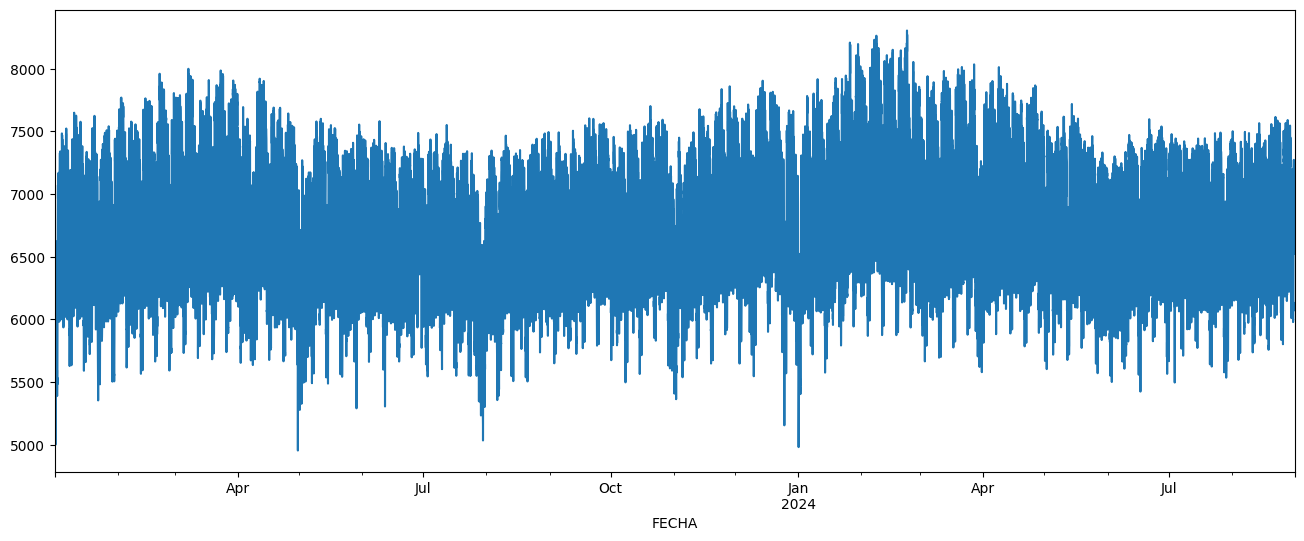

In [150]:
data.Demand.plot(figsize=(16,6))

### Analisis de tendencia(Explica sin codigo)

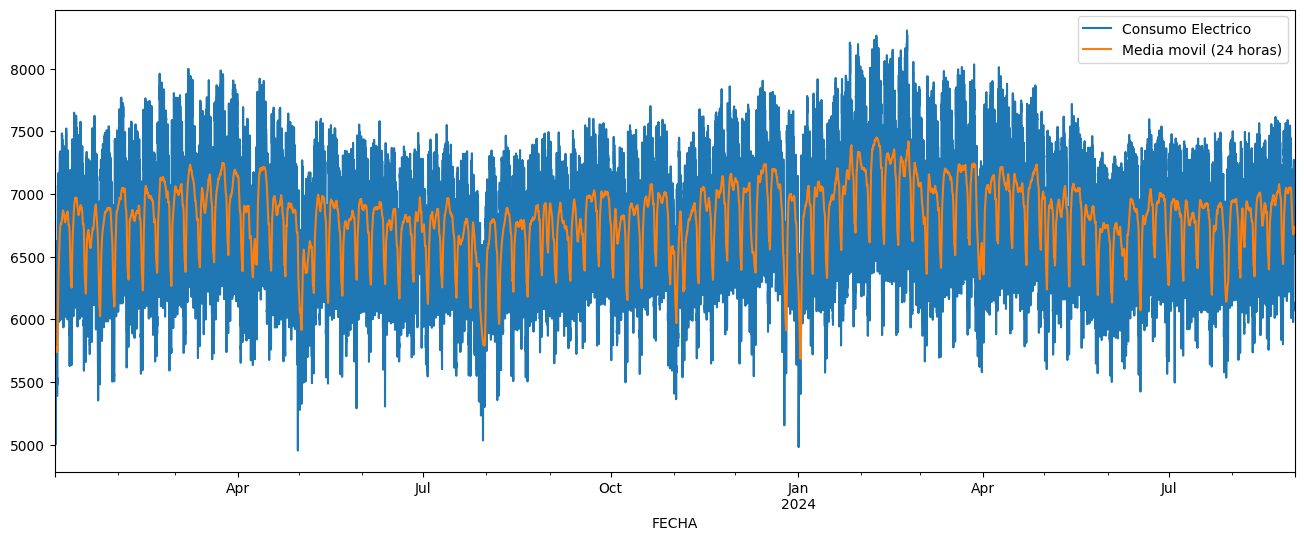

In [151]:
data.Demand.plot(figsize=(16,6),label="Consumo Electrico")
data.Demand.rolling(48).mean().plot(label='Media movil (24 horas)')
plt.legend()
plt.show()

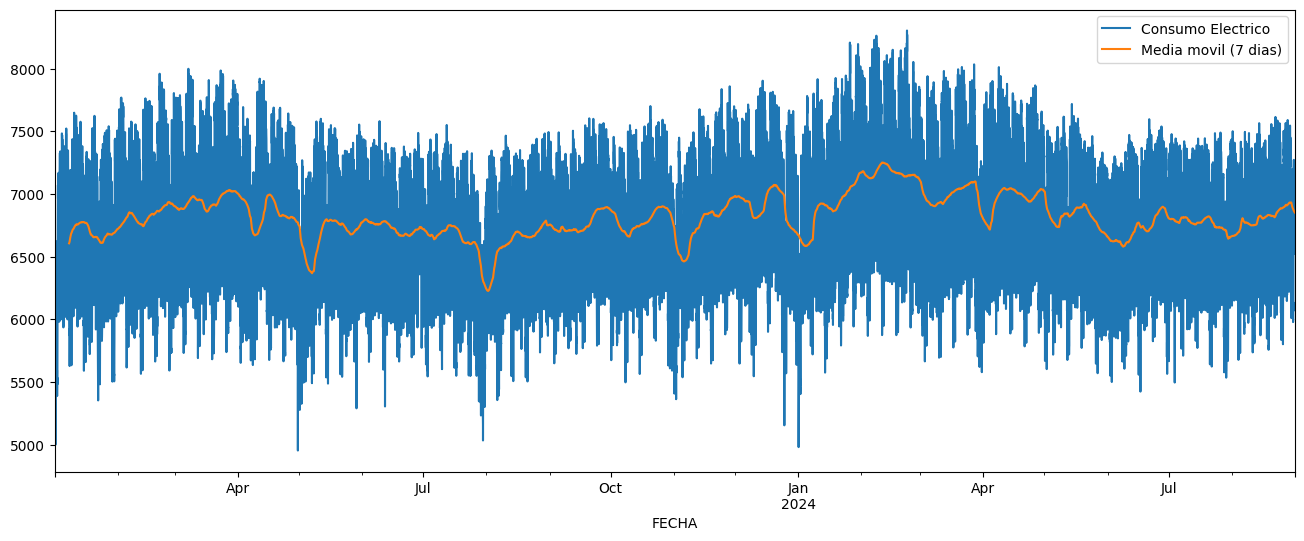

In [152]:
data.Demand.plot(figsize=(16,6),label="Consumo Electrico")
data.Demand.rolling(48*7).mean().plot(label='Media movil (7 dias)')
plt.legend()
plt.show()

## Featuring engineers

### Efecto Ciclico(Explica sin codigo)

In [153]:
data['ciclo'] = data.index.map(lambda x: (x.hour * 60  + x.minute) / (24*60))#ciclo de tiempo diario permite capturar las horas del dia y que el modelo aprenda el momento en que se produce el consumo electrico

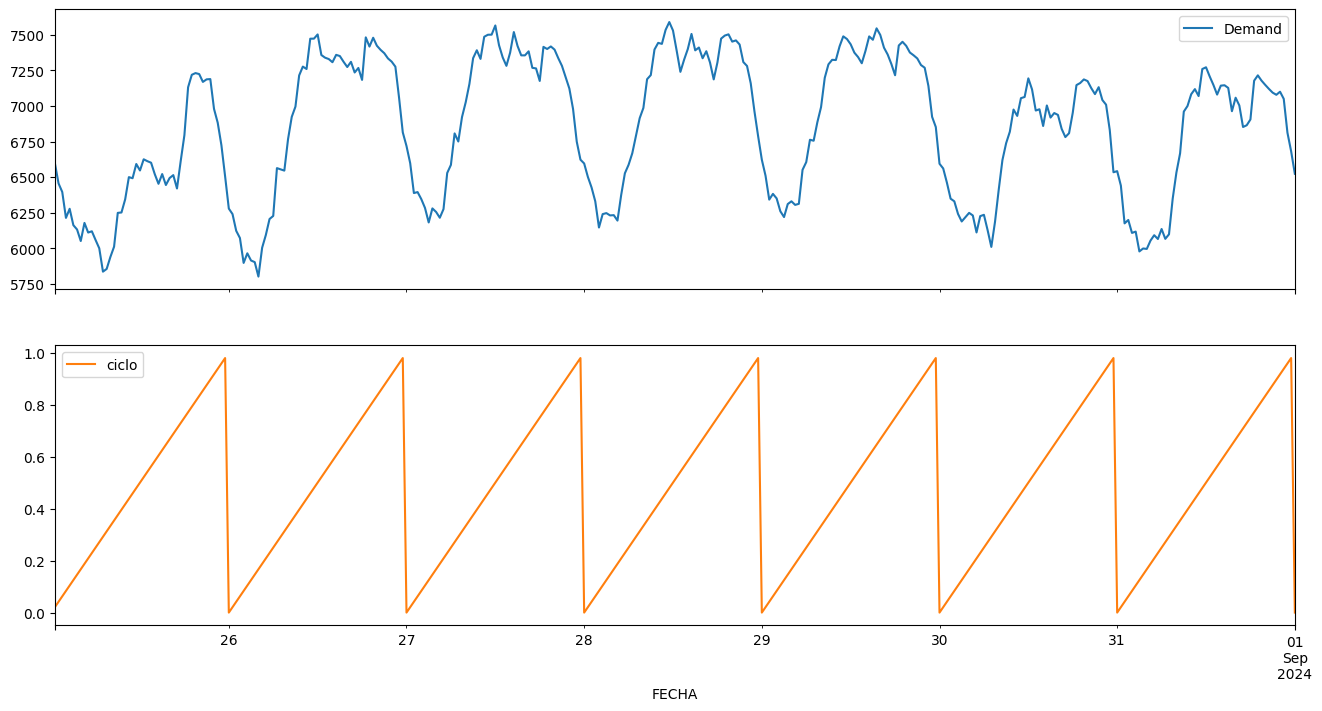

In [154]:
data[['Demand','ciclo']][-48*7:].plot(figsize=(16,8),subplots=True)
plt.show()

El gráfico superior muestra el consumo eléctrico en Megavatios(eje Y) sobre el tiempo(eje X).
El gráfico inferior divide las horas del día en una escala de 0 a 1 donde 0 es las 00:00 del día y 1 es 23:59 del mismo día.

### Efecto Diario(Explica con codigo)

In [155]:
days_translation = {
    'Monday': '1Lunes',
    'Tuesday': '2Martes',
    'Wednesday': '3Miércoles',
    'Thursday': '4Jueves',
    'Friday': '5Viernes',
    'Saturday': '6Sábado',
    'Sunday': '0Domingo'
}

In [156]:
months_translation = {
    'January': '01Enero',
    'February': '02Febrero',
    'March': '03Marzo',
    'April': '04Abril',
    'May': '05Mayo',
    'June': '06Junio',
    'July': '07Julio',
    'August': '08Agosto',
    'September': '09Septiembre',
    'October': '10Octubre',
    'November': '11Noviembre',
    'December': '12Diciembre'
}

In [157]:
data['dia'] = data.index.day_name().map(days_translation)

In [158]:
#data['mes'] = data.index.month_name().map(months_translation)

In [159]:
data2 = pd.get_dummies(data,columns=['dia'], dtype=int)

In [160]:
data2.columns

Index(['Demand', 'ciclo', 'dia_0Domingo', 'dia_1Lunes', 'dia_2Martes',
       'dia_3Miércoles', 'dia_4Jueves', 'dia_5Viernes', 'dia_6Sábado'],
      dtype='object')

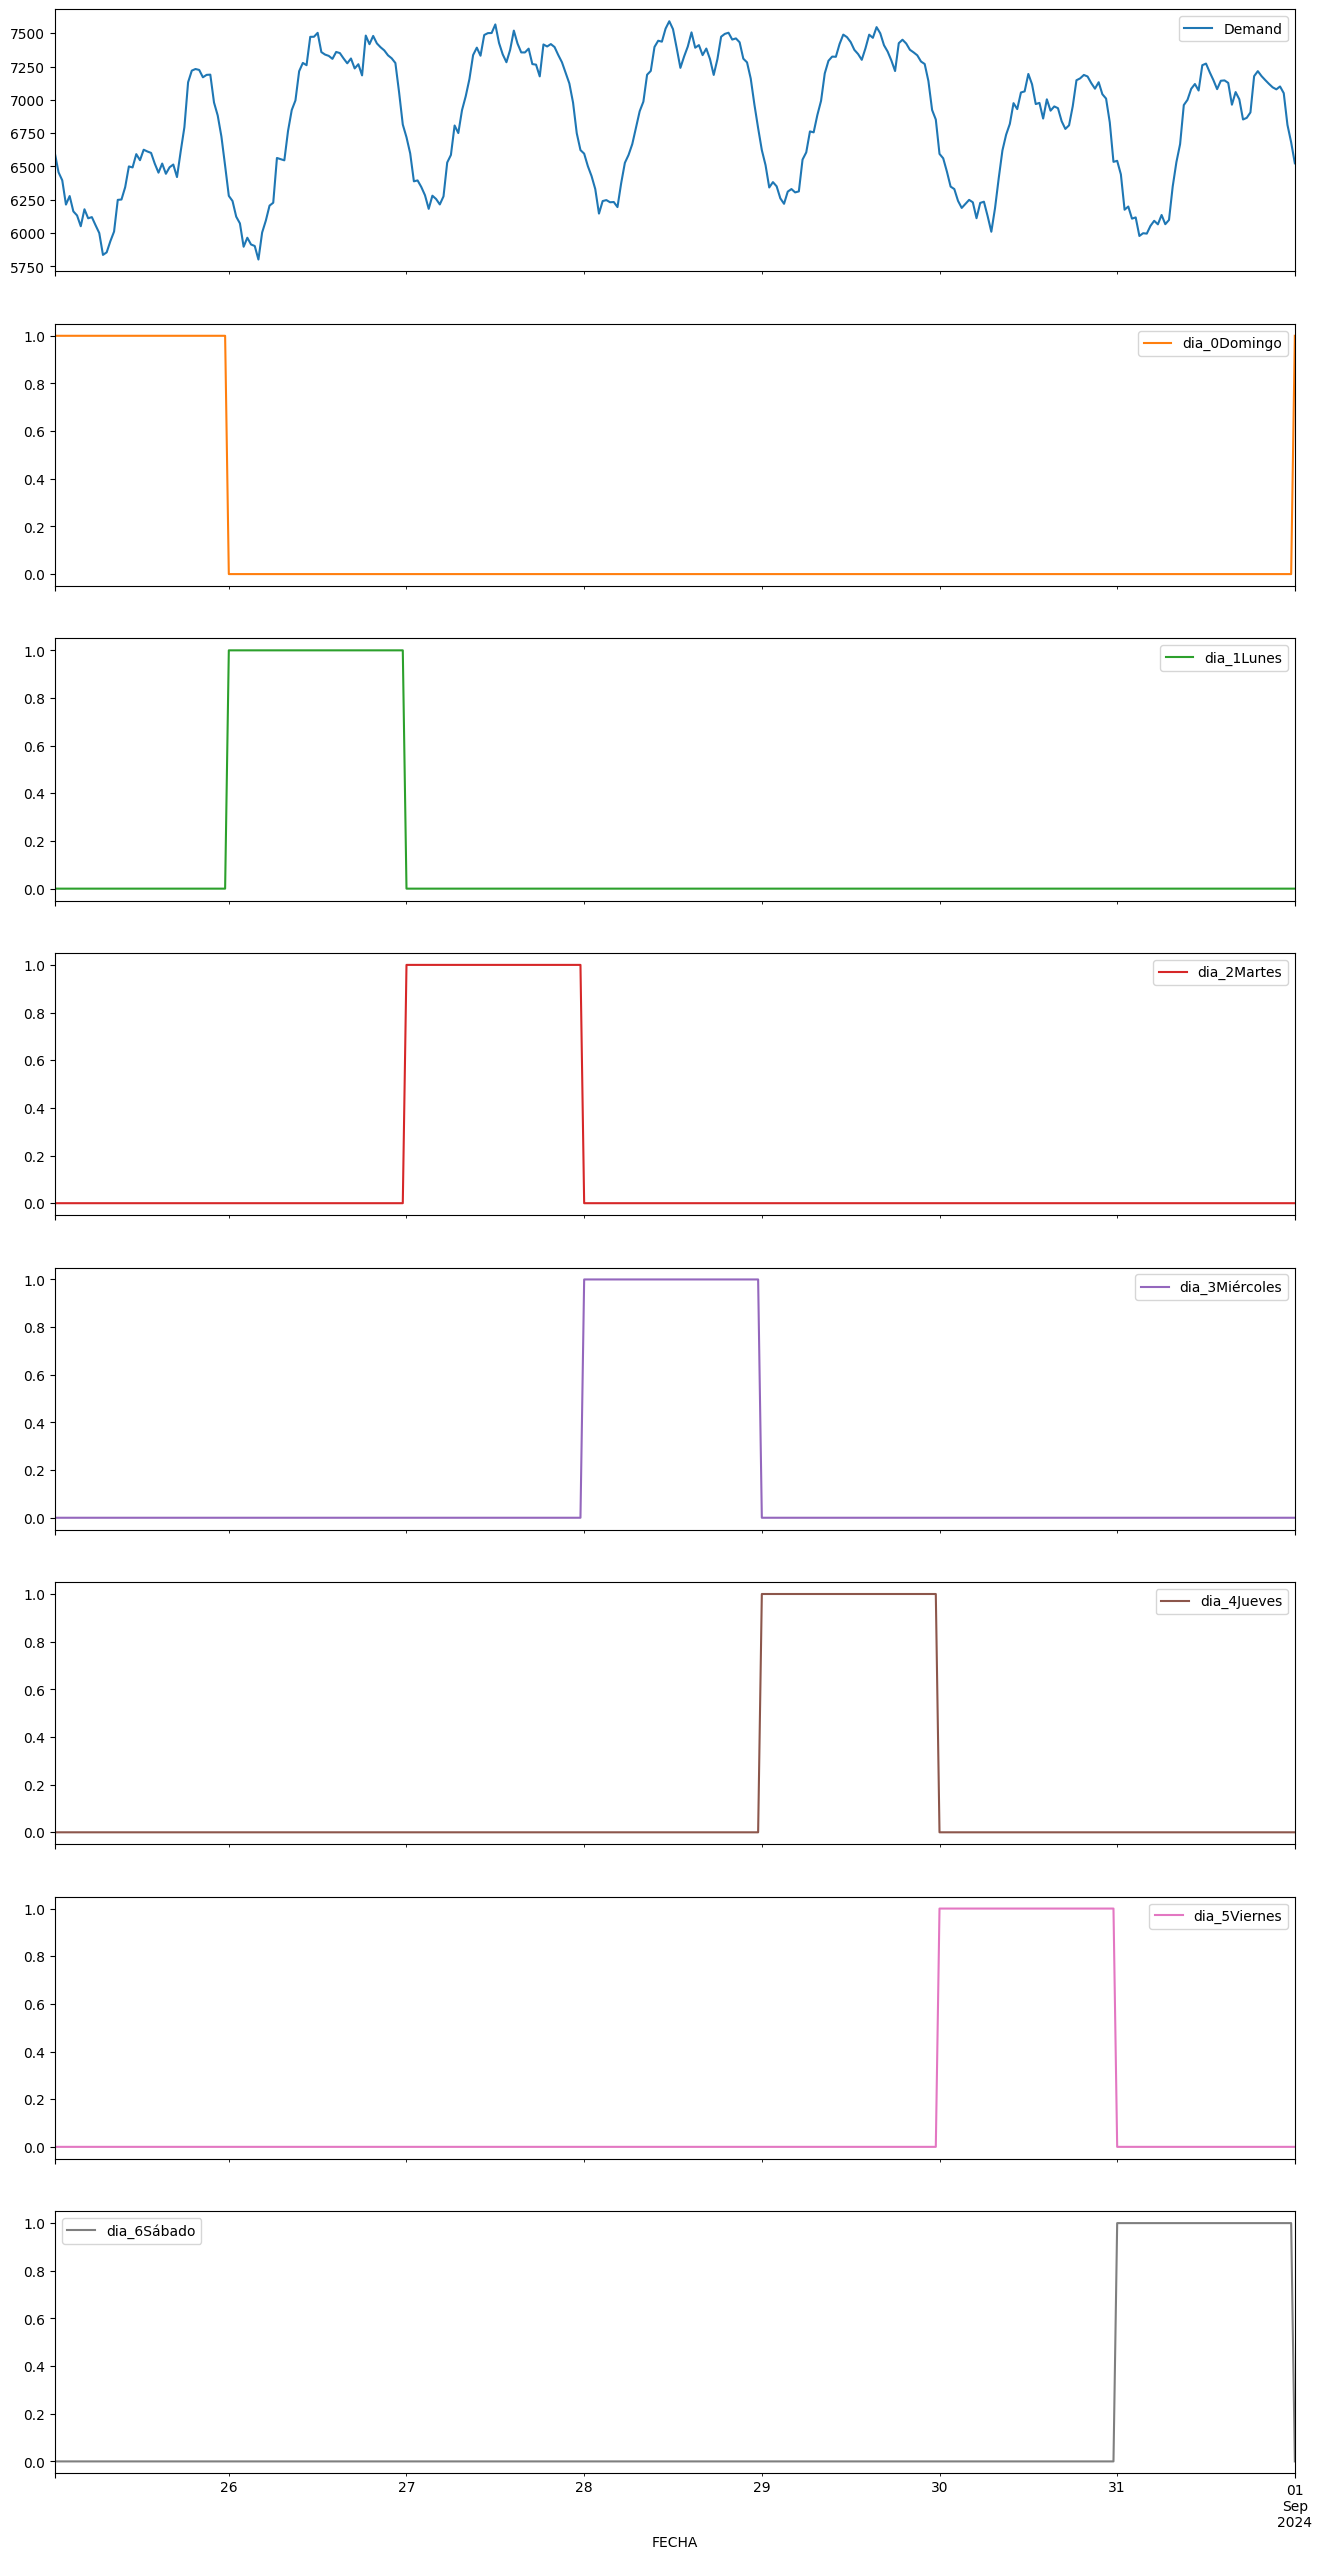

In [161]:
data2[['Demand','dia_0Domingo','dia_1Lunes','dia_2Martes','dia_3Miércoles','dia_4Jueves','dia_5Viernes','dia_6Sábado']][-48*7:].plot(figsize=(16,32),subplots=True)
plt.show()

### Efecto Feriado(Explica con codigo)

In [162]:
import holidays

In [163]:
pe = holidays.Peru(years=[2023,2024],observed=True)
data2['feriado'] = data2.index.normalize().isin(pe).astype(int)

C:\Users\Juan\AppData\Local\Temp\ipykernel_11064\2234722960.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  data2['feriado'] = data2.index.normalize().isin(pe).astype(int)


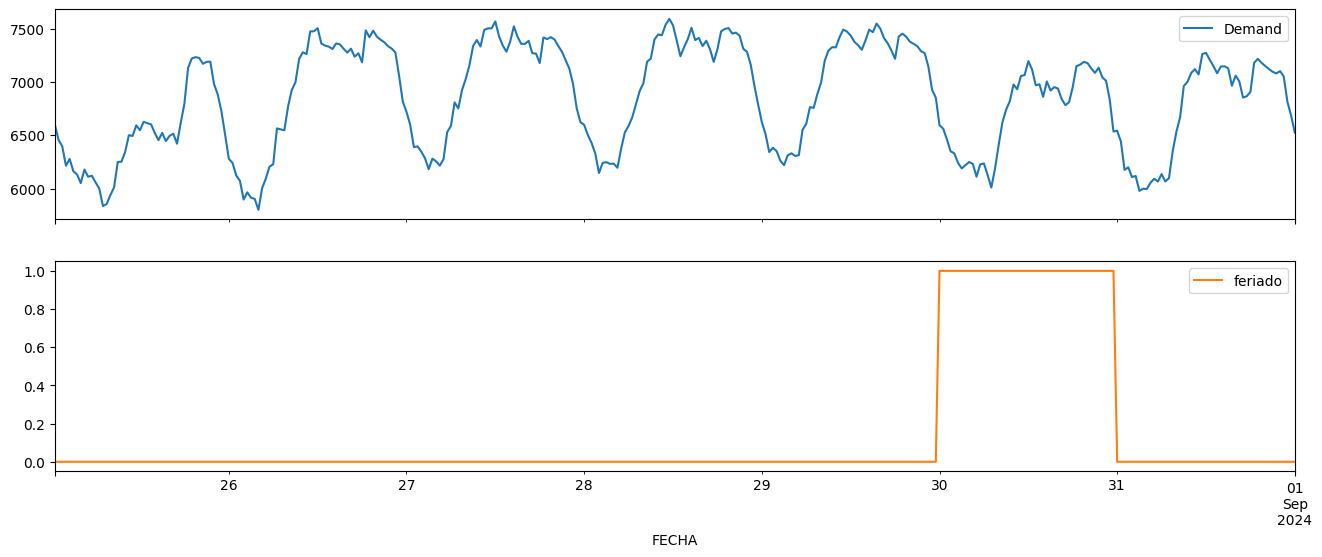

In [164]:
data2[['Demand','feriado']][-48*7:].plot(figsize=(16,6),subplots=True)
plt.show()

In [165]:
data2.head()

,Demand,ciclo,dia_0Domingo,dia_1Lunes,dia_2Martes,dia_3Miércoles,dia_4Jueves,dia_5Viernes,dia_6Sábado,feriado
FECHA,,,,,,,,,,
2023-01-01 00:30:00,6120.78000,0.020833,1,0,0,0,0,0,0,1
2023-01-01 01:00:00,6010.91339,0.041667,1,0,0,0,0,0,0,1
2023-01-01 01:30:00,5946.83300,0.062500,1,0,0,0,0,0,0,1
2023-01-01 02:00:00,5846.17000,0.083333,1,0,0,0,0,0,0,1
2023-01-01 02:30:00,5756.13500,0.104167,1,0,0,0,0,0,0,1


In [166]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 29232 entries, 2023-01-01 00:30:00 to 2024-09-01 00:00:00
Freq: 30min
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Demand          29232 non-null  float64
 1   ciclo           29232 non-null  float64
 2   dia_0Domingo    29232 non-null  int64  
 3   dia_1Lunes      29232 non-null  int64  
 4   dia_2Martes     29232 non-null  int64  
 5   dia_3Miércoles  29232 non-null  int64  
 6   dia_4Jueves     29232 non-null  int64  
 7   dia_5Viernes    29232 non-null  int64  
 8   dia_6Sábado     29232 non-null  int64  
 9   feriado         29232 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 2.5 MB


## Modelamiento

### Particion de datos(Explica con codigo)

In [167]:
steps = 48*7#separar la ultima semana
x_train = data2.drop(columns='Demand')[:-steps]
x_test  = data2.drop(columns='Demand')[-steps:]
y_train = data2['Demand'][:-steps]
y_test  = data2['Demand'][-steps:]

### Modelo autorregresivo (multivariado)(Explica sin codigo) con n_estimator = 250

In [168]:
# Hyperparameters: grid search
# ==============================================================================
forecaster = ForecasterRecursive(
                 regressor = XGBRegressor(random_state=123),
                 lags      = 48
             )

In [169]:
len(x_train)

28896

In [170]:
# Training and validation folds
cv = TimeSeriesFold(
      steps              = 48,#evaluar cada 24 horas  
      initial_train_size = int(len(x_train) - steps),# inicialmente entrena con todo menos la última semana
      refit              = False,
      fixed_train_size   = False
    )

In [171]:
# Candidate values for lags
lags_grid = [1,48,96]

In [172]:
# Candidate values for regressor's hyperparameters
param_grid = {
    'n_estimators': [250],
    'max_depth': [3,5,7]
}

In [173]:
results_grid = grid_search_forecaster(
                    forecaster  = forecaster,
                    y           = y_train,
                    cv          = cv,
                    exog        = x_train,
                    param_grid  = param_grid,
                    lags_grid   = lags_grid,
                    metric      = 'mean_squared_error',
                    return_best = True,
                    n_jobs      = 'auto',
                    verbose     = False)

lags grid: 100%|██████████| 3/3 [01:33<00:00, 31.26s/it]


`Forecaster` refitted using the best-found lags and parameters, and the whole data set: 
  Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96] 
  Parameters: {'max_depth': 5, 'n_estimators': 250}
  Backtesting metric: 8252.548161917945


El backtesting metric indica el mejor MSE(Mean Squared Error) obtenido con estos hiperparámetros y es de 8252.5481 con los datos de entrenamiento.

## Predicciones con XGBoost Regressor

In [174]:
regressor = XGBRegressor(n_estimators= 250, max_depth=5, random_state=123)
forecaster = ForecasterRecursive(
                 regressor = regressor,
                 lags      = 48
             )
forecaster.fit(y=y_train, exog=x_train)

In [175]:
predictions = forecaster.predict(steps= steps, exog=x_test)

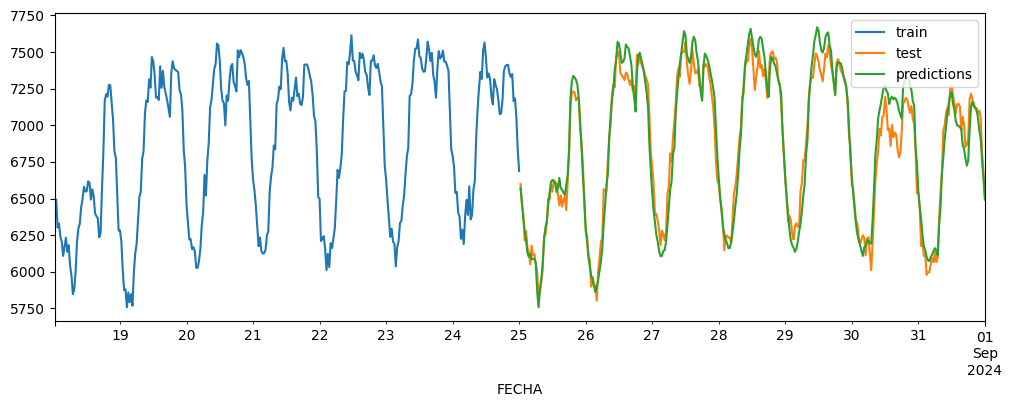

In [176]:
fig, ax = plt.subplots(figsize=(12,4))
y_train[-steps:].plot(ax=ax, label='train')
y_test.plot(ax=ax, label='test')
predictions.plot(ax=ax, label='predictions')
ax.legend()
plt.show()

In [177]:
error_mse1 = mean_squared_error(
                y_true = y_test,
                y_pred = predictions
            )
print(f"Test error 1 (MSE): {error_mse1}")

Test error 1 (MSE): 12955.894731346538


In [178]:
forecaster = ForecasterRecursive(
                 regressor = regressor,
                 lags      = 48
             )

In [179]:
cv = TimeSeriesFold(
      steps              = 48,
      initial_train_size = int(len(x_train) - steps),
      refit              = False,
      fixed_train_size   = False
    )

### Probando grid_search_forecaster con varios hiperparámetros

In [180]:
# Candidate values for lags
lags_grid = [1,48,96]

# Candidate values for regressor's hyperparameters
param_grid = {
    'regressor__n_estimators': [100, 250, 500, 750],
    'regressor__max_depth': [3, 5, 8]
}

In [181]:
results_xgb = grid_search_forecaster(
                    forecaster  = forecaster,
                    y           = y_train,
                    exog        = x_train,
                    cv          = cv,
                    param_grid  = param_grid,
                    lags_grid   = lags_grid,
                    metric      = 'mean_squared_error',
                    return_best = True,
                    n_jobs      = 'auto',
                    verbose     = False
                )

#print("Resultados de la validación cruzada:", results_grid)


lags grid:   0%|          | 0/3 [00:00<?, ?it/s]c:\Users\Juan\anaconda3\envs\series\Lib\site-packages\xgboost\training.py:183: UserWarning: [09:46:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "regressor__max_depth", "regressor__n_estimators" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Juan\anaconda3\envs\series\Lib\site-packages\xgboost\training.py:183: UserWarning: [09:46:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "regressor__max_depth", "regressor__n_estimators" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Juan\anaconda3\envs\series\Lib\site-packages\xgboost\training.py:183: UserWarning: [09:46:05] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "regressor__max_depth", "regressor__n_estimators" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Juan\anaconda3\envs\series\Lib\site-packages\xgbo

`Forecaster` refitted using the best-found lags and parameters, and the whole data set: 
  Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96] 
  Parameters: {'regressor__max_depth': 3, 'regressor__n_estimators': 100}
  Backtesting metric: 8252.548161917945


In [182]:
best_params = results_xgb.loc[results_xgb['mean_squared_error'].idxmin()]
best_lags = best_params['lags']
cv_mse = best_params['mean_squared_error']
print(f"\nMejores hiperparámetros encontrados: {best_params['params']}")
print(f"Mejor valor de lags: {best_lags}")
print(f"Mejor error en validación cruzada (MSE): {cv_mse}")


Mejores hiperparámetros encontrados: {'regressor__max_depth': 3, 'regressor__n_estimators': 100}
Mejor valor de lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96]
Mejor error en validación cruzada (MSE): 8252.548161917945


In [183]:
regressor_xgb = XGBRegressor(n_estimators=100, max_depth=3, random_state=123)
forecaster = ForecasterRecursive(
                 regressor = regressor_xgb,
                 lags      = 96
             )
forecaster.fit(y = y_train, exog = x_train)

In [184]:
predictions_xgb = forecaster.predict(steps=steps, exog=x_test)

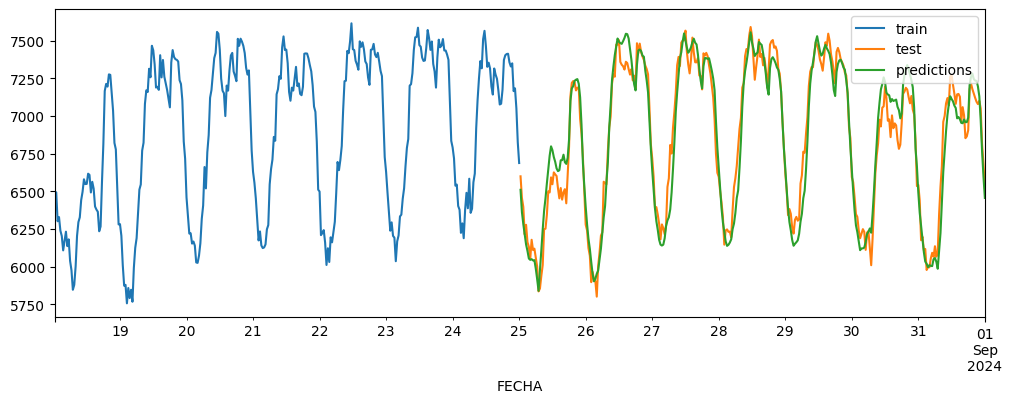

In [185]:
fig, ax = plt.subplots(figsize=(12,4))
y_train[-steps:].plot(ax=ax, label='train')
y_test.plot(ax=ax, label='test')
predictions_xgb.plot(ax=ax, label='predictions')
ax.legend()
plt.show()
#Extraer el gráfico como PNG para incluir en el reporte
fig.savefig("images/predicciones_xgboost.png")

In [186]:
error_mse_xgb = mean_squared_error(
                y_true = y_test,
                y_pred = predictions_xgb
            )
print(f"Test error xgb (MSE): {error_mse_xgb}")
print(f"Test error xgb RMSE: {error_mse_xgb ** 0.5}")

Test error xgb (MSE): 15147.191385262618
Test error xgb RMSE: 123.07392650461193


## Predicciones con LightGBM Regressor

In [ ]:
# Definir el regresor de LightGBM
regressor_lgbm = LGBMRegressor(random_state=123,verbose=0)

# Inicializar el forecaster con el nuevo regresor
forecaster_lgbm = ForecasterRecursive(
    regressor=regressor_lgbm,
    lags=48  # El mejor valor de 'lags' que encontraste
)
# Candidate values for lags
lags_grid = [1,48,96]


# Definir la cuadrícula de parámetros para LightGBM

param_grid_lgbm = {
    'regressor__n_estimators': [100, 250, 500, 750],
    'regressor__num_leaves': [31, 63, 127],
    'regressor__learning_rate': [0.01, 0.05, 0.1]
}

In [199]:
# Ejecutar la validación cruzada para encontrar los mejores parámetros
results_lgbm = grid_search_forecaster(
    forecaster=forecaster_lgbm,
    y=y_train,
    exog=x_train,
    cv=cv,
    param_grid=param_grid_lgbm,
    lags_grid=lags_grid,  # Para este grid_search puedes fijar el lags
    metric='mean_squared_error',
    return_best=True,
    n_jobs='auto',
    verbose=False
)


lags grid:   0%|          | 0/3 [00:00<?, ?it/s]

lags grid: 100%|██████████| 3/3 [02:06<00:00, 42.31s/it]


`Forecaster` refitted using the best-found lags and parameters, and the whole data set: 
  Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96] 
  Parameters: {'regressor__n_estimators': 100, 'regressor__num_leaves': 31}
  Backtesting metric: 10199.264769097668


In [201]:
regressor_lgbm = LGBMRegressor(n_estimators=100, num_leaves=31, random_state=123)
forecaster = ForecasterRecursive(
    regressor=regressor_lgbm,
    lags=96
)

forecaster.fit(y = y_train, exog = x_train)

In [202]:
predictions_lgbm = forecaster.predict(steps=steps, exog=x_test)

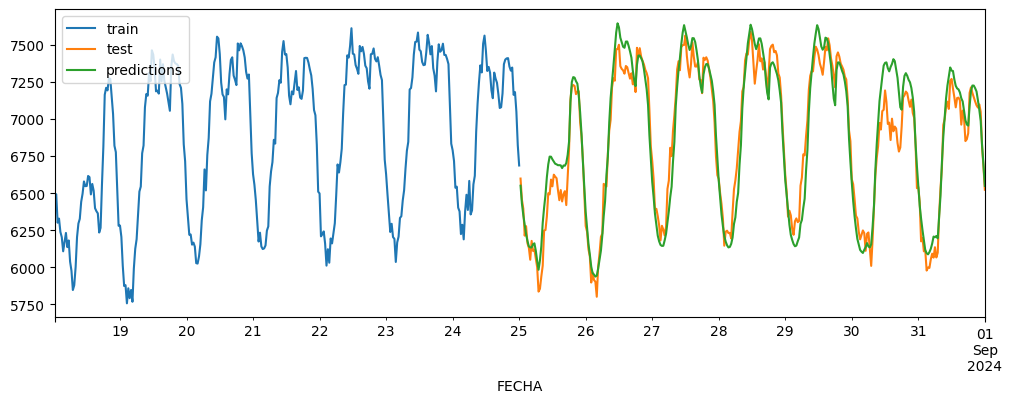

In [203]:
fig, ax = plt.subplots(figsize=(12,4))
y_train[-steps:].plot(ax=ax, label='train')
y_test.plot(ax=ax, label='test')
predictions_lgbm.plot(ax=ax, label='predictions')
ax.legend()
plt.show()
#Extraer el gráfico como PNG para incluir en el reporte
fig.savefig("images/predicciones_lgbm.png")

In [204]:
error_mse_lgbm = mean_squared_error(
                y_true = y_test,
                y_pred = predictions_lgbm
            )
print(f"Test error lgbm (MSE): {error_mse_xgb}")
print(f"Test error lgbm RMSE: {error_mse_xgb ** 0.5}")

Test error lgbm (MSE): 15147.191385262618
Test error lgbm RMSE: 123.07392650461193


## Predicciones con CatBoost Regressor

In [211]:


# Definir el regresor de CatBoost
regressor_catboost = CatBoostRegressor(random_state=123, verbose=0)

# Inicializar el forecaster con el nuevo regresor
forecaster_catboost = ForecasterRecursive(
    regressor=regressor_catboost,
    lags=48 # El mejor valor de 'lags' que encontraste
)

# Definir la cuadrícula de parámetros para CatBoost
# CatBoost a menudo se ajusta bien con los valores por defecto
lags_grid = [1, 48, 96]
param_grid_catboost = {
    'regressor__iterations': [100, 250, 500, 750],
    'regressor__depth': [3, 5, 8],
    'regressor__learning_rate': [0.01, 0.05, 0.1]
}

# Ejecutar la validación cruzada
results_catboost = grid_search_forecaster(
    forecaster=forecaster_catboost,
    y=y_train,
    exog=x_train,
    param_grid=param_grid_catboost,
    lags_grid=lags_grid, # Para este grid_search puedes fijar el lags
    cv=cv,
    metric='mean_squared_error',
    return_best=True,
    n_jobs='auto',
    verbose=False
)

# Continúa con los pasos de evaluación final

lags grid:   0%|          | 0/3 [00:00<?, ?it/s]


CatBoostError: catboost/private/libs/options/plain_options_helper.cpp:512: Unknown option {regressor__learning_rate} with value "0.01"

In [ ]:
best_params = results_catboost.loc[results_catboost['mean_squared_error'].idxmin()]
best_lags = best_params['lags']
cv_mse = best_params['mean_squared_error']
print(f"\nMejores hiperparámetros encontrados: {best_params['params']}")
print(f"Mejor valor de lags: {best_lags}")
print(f"Mejor error en validación cruzada (MSE): {cv_mse}")

In [ ]:
regressor_catboost = CatBoostRegressor(n_estimators=, max_depth=, random_state=123)
forecaster = ForecasterRecursive(
    regressor=regressor_catboost,
    lags=
)

forecaster.fit(y = y_train, exog = x_train)

In [ ]:
predictions_catboost = forecaster.predict(steps=steps, exog=x_test)

In [ ]:
fig, ax = plt.subplots(figsize=(12,4))
y_train[-steps:].plot(ax=ax, label='train')
y_test.plot(ax=ax, label='test')
predictions_catboost.plot(ax=ax, label='predictions')
ax.legend()
plt.show()
#Extraer el gráfico como PNG para incluir en el reporte
fig.savefig("images/predicciones_catboost.png")

In [ ]:
error_mse_catboost = mean_squared_error(
                y_true = y_test,
                y_pred = predictions_catboost
            )
print(f"Test error catboost (MSE): {error_mse_catboost}")
print(f"Test error catboost RMSE: {error_mse_catboost ** 0.5}")